In [3]:
%pip install qiskit==2.2.3 qiskit-aer==0.17.2 numpy==2.0.2 scipy==1.13.1 matplotlib==3.9.4 ipykernel==6.29.5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 11.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 11.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 11.3 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: ipykernel━━━━━━╺━━━━━━━━ 7/9 [matplotlib]
    Found existing installation: ipykernel 6.31.0━━━━━━━━ 7/9 [matplotlib]
    Uninstalling ipykernel-6.31.0:━╺━━━━━━━━ 7/9 [matplotlib]
      Successfully uninstalled ipykernel-6.31.00m━━━━━━━━ 7/9 [matplotlib]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [ipykernel]0m [matplotlib]
Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys
import numpy
import scipy
import matplotlib
import qiskit
import qiskit_aer

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)

%pip check

/var/folders/b4/3gqrgw9x7819bqp170k0wp3h0000gp/T/ipykernel_69888/2750344372.py:5: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  import qiskit


Python: 3.9.6
NumPy: 2.0.2
SciPy: 1.13.1
Matplotlib: 3.9.4
Qiskit: 2.2.3
Aer: 0.17.2
No broken requirements found.
Note: you may need to restart the kernel to use updated packages.


# GridQ: Generator Selection Using QAOA

**Participant:** Kshitiz Khatiwada  
**Group:** GridQ  
**University:** University of Arkansas at Monticello  
**Academic programs:** Double Major in Computer Information Systems and Mathematics 
**Career level:** Undergraduate student - Junior 
**Track:** Quantum Approximate Optimization Algorithm (QAOA)  
**Requested category:** Rising-star  

## 1. Problem Statement

This project considers four electricity generators with different available
capacities and fixed selection costs. The objective is to select the
lowest-cost combination whose total available capacity meets or exceeds
the required demand.

Each generator has a binary decision variable:

- `0`: the generator is not selected.
- `1`: the generator is selected.

| Generator | Available capacity | Fixed cost |
|-----------|-------------------:|-----------:|
| 1 | 2 | 3 |
| 2 | 4 | 5 |
| 3 | 5 | 6 |
| 4 | 7 | 8 |

**Required demand: 9 capacity units.**

The mathematical problem is:

$$
\min C(x)=3x_0+5x_1+6x_2+8x_3
$$

subject to:

$$
2x_0+4x_1+5x_2+7x_3 \geq 9,
\qquad x_i\in\{0,1\}.
$$

The values are synthetic and use common capacity and cost units.
The model represents available capacity; it does not require every
selected generator to produce its full capacity.

## 2. Motivation and Project Goal

I chose this problem because its decisions are easy to interpret and
its small size allows every possible selection to be checked exactly.

First, I establish the correct answer using classical enumeration.
Next, I encode the capacity constraint as a QUBO and apply QAOA.
I will compare the resulting decisions with the exact classical answer
and investigate how simulated gate noise affects solution quality.

This is a simplified, single-period generator-selection model.
It does not include continuous power dispatch, operating schedules,
or transmission-network constraints.

## 3. Classical Baseline

With four generators, there are \(2^4 = 16\) possible on/off selections.

I check every selection, calculate its capacity and cost, and keep those
whose capacity meets the demand. Among the feasible selections, I find
the minimum cost and retain every selection with that cost.

This exhaustive search provides the exact answer against which I will
compare QAOA.

In [2]:
from itertools import product

# Our four-generator problem.
costs = [3, 5, 6, 8]
capacities = [2, 4, 5, 7]
demand = 9

best_cost = float("inf")
best_combinations = []
feasible_count = 0

print("Combination | Capacity | Cost | Feasible")
print("-" * 43)

for combination in product([0, 1], repeat=4):
    total_capacity = sum(
        bit * capacity
        for bit, capacity in zip(combination, capacities)
    )
    total_cost = sum(
        bit * cost
        for bit, cost in zip(combination, costs)
    )
    feasible = total_capacity >= demand

    bit_string = "".join(str(bit) for bit in combination)
    print(
        f"{bit_string:^11} | {total_capacity:^8} | "
        f"{total_cost:^4} | {'Yes' if feasible else 'No'}"
    )

    if feasible:
        feasible_count += 1

        if total_cost < best_cost:
            best_cost = total_cost
            best_combinations = [combination]

        elif total_cost == best_cost:
            best_combinations.append(combination)

print("\nFINAL RESULT")
print("Feasible combinations:", feasible_count)

if not best_combinations:
    print("No selection can meet demand.")
else:
    print("Minimum feasible cost:", best_cost)

    for combination in best_combinations:
        selected = [
            index + 1
            for index, bit in enumerate(combination)
            if bit == 1
        ]
        print("Optimal combination:", combination)
        print("Selected generators:", selected)

Combination | Capacity | Cost | Feasible
-------------------------------------------
   0000     |    0     |  0   | No
   0001     |    7     |  8   | No
   0010     |    5     |  6   | No
   0011     |    12    |  14  | Yes
   0100     |    4     |  5   | No
   0101     |    11    |  13  | Yes
   0110     |    9     |  11  | Yes
   0111     |    16    |  19  | Yes
   1000     |    2     |  3   | No
   1001     |    9     |  11  | Yes
   1010     |    7     |  9   | No
   1011     |    14    |  17  | Yes
   1100     |    6     |  8   | No
   1101     |    13    |  16  | Yes
   1110     |    11    |  14  | Yes
   1111     |    18    |  22  | Yes

FINAL RESULT
Feasible combinations: 9
Minimum feasible cost: 11
Optimal combination: (0, 1, 1, 0)
Selected generators: [2, 3]
Optimal combination: (1, 0, 0, 1)
Selected generators: [1, 4]


## 4. Encoding the Constraint as a QUBO

QUBO means Quadratic Unconstrained Binary Optimization. It expresses
the problem as one objective involving binary variables and products
of at most two variables.

Our original constraint is:

$$
\text{capacity} \geq 9.
$$

Introduce a nonnegative integer called slack, representing surplus capacity:

$$
\text{capacity} - 9 - s = 0.
$$

For example, capacity 12 requires slack 3. Capacity 7 would require
slack -2, which our nonnegative slack cannot represent.

The largest possible surplus is 18 - 9 = 9. Four binary variables
encode slack using:

$$
s=b_0+2b_1+4b_2+8b_3.
$$

These bits represent integers from 0 to 15, covering every required
surplus value. Values above 9 cannot satisfy the equality for this instance.

The penalized objective is:

$$
F(x,b)=3x_0+5x_1+6x_2+8x_3
+24(2x_0+4x_1+5x_2+7x_3-9-s)^2.
$$

A zero residual gives zero penalty. Any nonzero residual is an integer,
so its squared penalty is at least 24. Selecting all generators costs
22 and has a zero-penalty slack assignment. Therefore, an assignment
with a nonzero residual cannot minimize this objective.

Squaring a linear expression produces terms of degree at most two.
Because binary variables satisfy x² = x, this objective is a QUBO.

There are eight binary variables: four generator bits and four slack
bits. Our quantum encoding will therefore use eight qubits.

The following check is still classical enumeration. It verifies the
encoding before we construct a quantum circuit.

In [3]:
penalty_strength = 24
slack_weights = [1, 2, 4, 8]

best_energy = float("inf")
best_encoded_solutions = []
assignments_checked = 0

for generator_bits in product([0, 1], repeat=len(costs)):
    total_cost = sum(
        bit * cost
        for bit, cost in zip(generator_bits, costs)
    )
    total_capacity = sum(
        bit * capacity
        for bit, capacity in zip(generator_bits, capacities)
    )

    for slack_bits in product([0, 1], repeat=len(slack_weights)):
        assignments_checked += 1

        slack = sum(
            bit * weight
            for bit, weight in zip(slack_bits, slack_weights)
        )
        residual = total_capacity - demand - slack
        energy = total_cost + penalty_strength * residual**2

        solution = {
            "generator_bits": generator_bits,
            "slack_bits": slack_bits,
            "capacity": total_capacity,
            "cost": total_cost,
            "slack": slack,
            "residual": residual,
            "energy": energy,
        }

        if energy < best_energy:
            best_energy = energy
            best_encoded_solutions = [solution]
        elif energy == best_energy:
            best_encoded_solutions.append(solution)

print("Encoded assignments checked:", assignments_checked)
print("Minimum encoded energy:", best_energy)

for solution in best_encoded_solutions:
    print("\nOptimal encoded solution:")
    for name, value in solution.items():
        print(f"{name}: {value}")

# Compare the encoded optima with the original classical optima.
encoded_generator_choices = {
    solution["generator_bits"]
    for solution in best_encoded_solutions
}

assert best_energy == best_cost
assert encoded_generator_choices == set(best_combinations)
assert all(
    solution["residual"] == 0
    for solution in best_encoded_solutions
)

print("\nPASS: The encoding preserves both classical optima.")

Encoded assignments checked: 256
Minimum encoded energy: 11

Optimal encoded solution:
generator_bits: (0, 1, 1, 0)
slack_bits: (0, 0, 0, 0)
capacity: 9
cost: 11
slack: 0
residual: 0
energy: 11

Optimal encoded solution:
generator_bits: (1, 0, 0, 1)
slack_bits: (0, 0, 0, 0)
capacity: 9
cost: 11
slack: 0
residual: 0
energy: 11

PASS: The encoding preserves both classical optima.


## 5. Expanding the QUBO

Collect the eight binary variables in this order:

$$
y=(x_0,x_1,x_2,x_3,b_0,b_1,b_2,b_3).
$$

The residual can be written as:

$$
r=\sum_i w_i y_i-D,
$$

where:

$$
w=(2,4,5,7,-1,-2,-4,-8), \qquad D=9.
$$

Generator capacities have positive weights. Slack has negative weights
because it is subtracted from capacity.

Expanding the penalized objective gives:

$$
F(y)=k+\sum_i a_i y_i+\sum_{i<j}q_{ij}y_i y_j.
$$

The coefficients are:

$$
k=AD^2,
$$

$$
a_i=c_i+A(w_i^2-2Dw_i),
$$

$$
q_{ij}=2Aw_iw_j.
$$

Here A = 24, and the cost coefficients are:

$$
c=(3,5,6,8,0,0,0,0).
$$

Slack bits have no direct selection cost.

For example:

- The constant is 24 × 9² = 1944.
- The coefficient of x₀ is 3 + 24(2² - 2 × 9 × 2) = -765.
- The coefficient of x₀x₁ is 2 × 24 × 2 × 4 = 384.

Negative coefficients are valid. The complete expression, including
its constant, equals our original cost-plus-penalty objective.

I verify the expansion by comparing both expressions for all 256
binary assignments.

In [5]:
import numpy as np

variable_names = [
    "x0", "x1", "x2", "x3",
    "b0", "b1", "b2", "b3",
]

# Generator capacities are positive; slack weights are negative.
weights = np.array(capacities + [-w for w in slack_weights])

# Only generator bits contribute directly to selection cost.
cost_vector = np.array(costs + [0] * len(slack_weights))

num_variables = len(weights)

qubo_constant = penalty_strength * demand**2

qubo_linear = (
    cost_vector
    + penalty_strength * (weights**2 - 2 * demand * weights)
)

# Store each pair once, with i < j.
qubo_pairs = {
    (i, j): 2 * penalty_strength * weights[i] * weights[j]
    for i in range(num_variables)
    for j in range(i + 1, num_variables)
}

print("Constant:", qubo_constant)

print("\nLinear coefficients:")
for name, coefficient in zip(variable_names, qubo_linear):
    print(f"{name}: {coefficient}")

print("\nPair coefficients:")
for (i, j), coefficient in qubo_pairs.items():
    print(f"{variable_names[i]} * {variable_names[j]}: {coefficient}")

# Check the expanded QUBO against the original expression.
checked = 0

for bits in product([0, 1], repeat=num_variables):
    y = np.array(bits)

    direct_energy = (
        cost_vector @ y
        + penalty_strength * (weights @ y - demand)**2
    )

    expanded_energy = (
        qubo_constant
        + qubo_linear @ y
        + sum(
            coefficient * y[i] * y[j]
            for (i, j), coefficient in qubo_pairs.items()
        )
    )

    assert direct_energy == expanded_energy, (
        f"Mismatch for {bits}: "
        f"{direct_energy} versus {expanded_energy}"
    )

    checked += 1

print(f"\nPASS: Both expressions agree for all {checked} assignments.")

Constant: 1944

Linear coefficients:
x0: -765
x1: -1339
x2: -1554
x3: -1840
b0: 456
b1: 960
b2: 2112
b3: 4992

Pair coefficients:
x0 * x1: 384
x0 * x2: 480
x0 * x3: 672
x0 * b0: -96
x0 * b1: -192
x0 * b2: -384
x0 * b3: -768
x1 * x2: 960
x1 * x3: 1344
x1 * b0: -192
x1 * b1: -384
x1 * b2: -768
x1 * b3: -1536
x2 * x3: 1680
x2 * b0: -240
x2 * b1: -480
x2 * b2: -960
x2 * b3: -1920
x3 * b0: -336
x3 * b1: -672
x3 * b2: -1344
x3 * b3: -2688
b0 * b1: 96
b0 * b2: 192
b0 * b3: 384
b1 * b2: 384
b1 * b3: 768
b2 * b3: 1536

PASS: Both expressions agree for all 256 assignments.


## 6. Converting the QUBO into an Ising Hamiltonian

A Hamiltonian is an operator that assigns an energy to a quantum state.
Here, its energies represent our optimization objective.

The Pauli-Z operator acts on the computational basis states as:

$$
Z|0\rangle=+|0\rangle,
\qquad
Z|1\rangle=-|1\rangle.
$$

Our binary variables take values 0 and 1, whereas Z has eigenvalues
+1 and -1. The conversion is:

$$
y_i=\frac{1-Z_i}{2}.
$$

This gives 0 for the state |0⟩ and 1 for the state |1⟩.

For a product of two binary variables:

$$
y_i y_j=\frac{1-Z_i-Z_j+Z_iZ_j}{4}.
$$

Substituting into the QUBO produces:

$$
H=E_{\mathrm{offset}}I+\sum_i h_i Z_i
+\sum_{i<j}J_{ij}Z_iZ_j.
$$

Here:

- I is the identity operator.
- hᵢ is the coefficient acting on qubit i.
- Jᵢⱼ is the interaction coefficient between qubits i and j.
- The offset adds the same energy to every state.

Starting from QUBO coefficients k, aᵢ, and qᵢⱼ:

$$
J_{ij}=\frac{q_{ij}}{4},
$$

$$
h_i=-\frac{a_i}{2}
-\frac14\sum_{j\ne i}q_{\min(i,j),\max(i,j)},
$$

$$
E_{\mathrm{offset}}
=k+\frac12\sum_i a_i+\frac14\sum_{i<j}q_{ij}.
$$

The state with the lowest Hamiltonian energy is called a ground state.
For this diagonal Hamiltonian, its computational-basis ground states
encode our optimal generator and slack assignments.

I check that the Ising expression and the QUBO agree for all 256
assignments.

In [6]:
# Convert the QUBO coefficients into Ising coefficients.
ising_h = -qubo_linear.astype(float) / 2

ising_J = {
    pair: float(coefficient) / 4
    for pair, coefficient in qubo_pairs.items()
}

for (i, j), coefficient in qubo_pairs.items():
    ising_h[i] -= coefficient / 4
    ising_h[j] -= coefficient / 4

ising_offset = float(
    qubo_constant
    + np.sum(qubo_linear) / 2
    + sum(qubo_pairs.values()) / 4
)

print("Ising energy offset:", ising_offset)

print("\nSingle-qubit Z coefficients:")
for name, coefficient in zip(variable_names, ising_h):
    print(f"{name}: {coefficient}")

print("\nNumber of ZZ interaction terms:", len(ising_J))

# Check the mapping for every possible binary assignment.
maximum_difference = 0.0

for bits in product([0, 1], repeat=num_variables):
    y = np.array(bits)

    # A bit 0 corresponds to Z eigenvalue +1.
    # A bit 1 corresponds to Z eigenvalue -1.
    z = 1 - 2 * y

    qubo_energy = (
        qubo_constant
        + qubo_linear @ y
        + sum(
            coefficient * y[i] * y[j]
            for (i, j), coefficient in qubo_pairs.items()
        )
    )

    ising_energy = (
        ising_offset
        + ising_h @ z
        + sum(
            coefficient * z[i] * z[j]
            for (i, j), coefficient in ising_J.items()
        )
    )

    difference = abs(float(qubo_energy - ising_energy))
    maximum_difference = max(maximum_difference, difference)

    assert np.isclose(
        qubo_energy, ising_energy, rtol=0, atol=1e-9
    ), f"Energy mismatch for assignment {bits}"

print("\nMaximum energy difference:", maximum_difference)
print("PASS: QUBO and Ising energies agree for all 256 assignments.")

Ising energy offset: 2435.0

Single-qubit Z coefficients:
x0: 358.5
x1: 717.5
x2: 897.0
x3: 1256.0
b0: -180.0
b1: -360.0
b2: -720.0
b3: -1440.0

Number of ZZ interaction terms: 28

Maximum energy difference: 0.0
PASS: QUBO and Ising energies agree for all 256 assignments.


## 7. Building a QAOA Circuit

QAOA stands for Quantum Approximate Optimization Algorithm.

It combines a quantum circuit with a classical optimizer. The circuit
has adjustable angles. The optimizer changes those angles to try to
reduce the expected value of our objective.

Our circuit has three stages:

1. Apply H to every qubit, creating an equal superposition of all
   256 encoded assignments.
2. Apply the cost layer, which changes phases according to the
   Ising objective.
3. Apply the mixer layer, which allows those phases to affect
   the probabilities of measuring different assignments.

One cost layer followed by one mixer layer is called depth p = 1.

The two angles for one layer are gamma and beta:

- Gamma controls the cost layer.
- Beta controls the mixer layer.

The cost layer uses RZ and RZZ rotations. The mixer uses RX rotations:

$$
R_Z(2\gamma h_i/S), \qquad
R_{ZZ}(2\gamma J_{ij}/S), \qquad
R_X(2\beta).
$$

The factor of two comes from the rotation convention:

$$
R_Z(\theta)=e^{-i\theta Z/2}.
$$

RZZ and RX use the corresponding convention for ZZ and X.

S is a positive scaling factor: the largest absolute nonconstant
Ising coefficient. Dividing by S preserves the optimal assignments
and changes the scale of the gamma parameter.

The constant energy offset is omitted from the circuit because it
only produces a global phase.

The angles below are demonstration values. They have not been optimized.

In [7]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Scale the cost coefficients used in the circuit.
energy_scale = max(
    np.max(np.abs(ising_h)),
    max(abs(value) for value in ising_J.values()),
)

def build_qaoa_circuit(gammas, betas):
    """Build a circuit with one cost/mixer layer per angle pair."""
    if len(gammas) != len(betas):
        raise ValueError("Provide one gamma and one beta per layer.")

    circuit = QuantumCircuit(num_variables)

    # Start with equal amplitudes for every encoded assignment.
    circuit.h(range(num_variables))

    for gamma, beta in zip(gammas, betas):
        # Cost layer: single-qubit Z terms.
        for i, coefficient in enumerate(ising_h):
            circuit.rz(
                2 * gamma * coefficient / energy_scale, i
            )

        # Cost layer: two-qubit ZZ terms.
        for (i, j), coefficient in ising_J.items():
            circuit.rzz(
                2 * gamma * coefficient / energy_scale, i, j
            )

        # Mixer layer.
        for i in range(num_variables):
            circuit.rx(2 * beta, i)

    return circuit

# Demonstration angles, not trained angles.
example_circuit = build_qaoa_circuit(
    gammas=[0.5],
    betas=[0.3],
)

print("Number of qubits:", example_circuit.num_qubits)
print("QAOA layers:", 1)
print("Gate counts:", dict(example_circuit.count_ops()))

# Compute exact ideal probabilities on a classical simulator.
example_state = Statevector.from_instruction(example_circuit)
example_probabilities = example_state.probabilities()

print("Number of probabilities:", len(example_probabilities))
print("Probability sum:", float(example_probabilities.sum()))

assert np.isclose(example_probabilities.sum(), 1.0)

# At gamma = beta = 0, only the initial H gates have an effect.
uniform_circuit = build_qaoa_circuit([0.0], [0.0])
uniform_probabilities = Statevector.from_instruction(
    uniform_circuit
).probabilities()

assert np.allclose(
    uniform_probabilities,
    np.full(2**num_variables, 1 / 2**num_variables),
)

print("PASS: Probabilities sum to 1.")
print("PASS: Zero angles produce the uniform distribution.")

# Display the first part of the circuit to keep the diagram readable.
print("\nCircuit preview: initial H gates and first four RZ gates")
preview = QuantumCircuit(num_variables)
for instruction in example_circuit.data[:12]:
    preview.append(instruction.operation, instruction.qubits)

print(preview.draw("text"))

Number of qubits: 8
QAOA layers: 1
Gate counts: {'rzz': 28, 'h': 8, 'rz': 8, 'rx': 8}
Number of probabilities: 256
Probability sum: 0.999999999999999
PASS: Probabilities sum to 1.
PASS: Zero angles produce the uniform distribution.

Circuit preview: initial H gates and first four RZ gates
     ┌───┐┌─────────────┐
q_0: ┤ H ├┤ Rz(0.24896) ├
     ├───┤├─────────────┤
q_1: ┤ H ├┤ Rz(0.49826) ├
     ├───┤├─────────────┤
q_2: ┤ H ├┤ Rz(0.62292) ├
     ├───┤├─────────────┤
q_3: ┤ H ├┤ Rz(0.87222) ├
     ├───┤└─────────────┘
q_4: ┤ H ├───────────────
     ├───┤               
q_5: ┤ H ├───────────────
     ├───┤               
q_6: ┤ H ├───────────────
     ├───┤               
q_7: ┤ H ├───────────────
     └───┘               


## 8. Measuring Solution Quality

A QAOA circuit produces a probability distribution over assignments.
We evaluate that distribution using four quantities:

1. Expected penalized objective: the average cost-plus-penalty value.
   This is the quantity our optimizer will minimize.
2. Feasibility probability: the probability that the generator selection
   meets demand, regardless of its slack bits.
3. Optimal generator probability: the probability of selecting either
   minimum-cost generator pair, regardless of its slack bits.
4. Optimal encoded probability: the probability of selecting an optimal
   generator pair together with its correct slack assignment.

The last two quantities are different. A useful generator choice can
appear with incorrect slack bits, giving a large penalty.

For uniform random assignments:

- 9 of 16 generator selections meet demand: feasibility is 56.25%.
- 2 of 16 generator selections are optimal: generator success is 12.5%.
- Only 2 of 256 complete assignments minimize the encoded objective:
  encoded success is 0.78125%.

These provide reference values for comparing our QAOA results.

Qiskit orders statevector probabilities by basis-state index.
Qubit 0 is the least significant bit of that index. I explicitly decode
each index into qubit order:

(x0, x1, x2, x3, b0, b1, b2, b3).

In [8]:
# Row k contains the bits for basis-state index k.
# Column i corresponds to qubit i.
basis_bits = np.array([
    [(index >> i) & 1 for i in range(num_variables)]
    for index in range(2**num_variables)
])

generator_assignments = basis_bits[:, :len(costs)]

basis_costs = generator_assignments @ np.array(costs)
basis_capacities = generator_assignments @ np.array(capacities)
basis_residuals = basis_bits @ weights - demand

basis_energies = (
    basis_costs
    + penalty_strength * basis_residuals**2
)

feasible_mask = basis_capacities >= demand

optimal_generator_mask = (
    feasible_mask
    & (basis_costs == best_cost)
)

optimal_encoded_mask = basis_energies == best_energy

def evaluate_probabilities(probabilities):
    """Summarize a distribution in Qiskit's basis-state order."""
    probabilities = np.asarray(probabilities, dtype=float)

    if probabilities.shape != (2**num_variables,):
        raise ValueError("Unexpected probability-array size.")

    if not np.isclose(probabilities.sum(), 1.0):
        raise ValueError("Probabilities must sum to 1.")

    return {
        "expected_energy": float(probabilities @ basis_energies),
        "feasibility_probability": float(
            probabilities[feasible_mask].sum()
        ),
        "optimal_generator_probability": float(
            probabilities[optimal_generator_mask].sum()
        ),
        "optimal_encoded_probability": float(
            probabilities[optimal_encoded_mask].sum()
        ),
    }

def print_metrics(label, metrics):
    print(f"\n{label}")
    print(f"Expected penalized objective: {metrics['expected_energy']:.4f}")
    print(
        "Feasibility probability: "
        f"{metrics['feasibility_probability']:.2%}"
    )
    print(
        "Optimal generator probability: "
        f"{metrics['optimal_generator_probability']:.2%}"
    )
    print(
        "Optimal encoded probability: "
        f"{metrics['optimal_encoded_probability']:.5%}"
    )

uniform_metrics = evaluate_probabilities(uniform_probabilities)
example_metrics = evaluate_probabilities(example_probabilities)

print_metrics("UNIFORM RANDOM BASELINE", uniform_metrics)
print_metrics("QAOA WITH DEMONSTRATION ANGLES", example_metrics)

assert np.isclose(
    uniform_metrics["feasibility_probability"], 9 / 16
)
assert np.isclose(
    uniform_metrics["optimal_generator_probability"], 2 / 16
)
assert np.isclose(
    uniform_metrics["optimal_encoded_probability"], 2 / 256
)

print("\nPASS: Decoded random-baseline probabilities are correct.")


UNIFORM RANDOM BASELINE
Expected penalized objective: 2435.0000
Feasibility probability: 56.25%
Optimal generator probability: 12.50%
Optimal encoded probability: 0.78125%

QAOA WITH DEMONSTRATION ANGLES
Expected penalized objective: 5434.0047
Feasibility probability: 35.04%
Optimal generator probability: 7.68%
Optimal encoded probability: 0.40533%

PASS: Decoded random-baseline probabilities are correct.


## 9. Training QAOA with COBYLA

QAOA is a hybrid algorithm: a classical optimizer chooses angles,
and a quantum circuit produces the distribution used to evaluate them.

For each trial:

1. COBYLA proposes gamma and beta.
2. I build the corresponding QAOA circuit.
3. An ideal statevector simulation computes its probabilities.
4. I calculate the expected penalized objective.
5. COBYLA uses that value to choose another trial.

COBYLA does not require derivatives of the objective.

I use depth p = 1 and three reproducible starting points, with seeds
42, 43, and 44. Different starting points can reach different solutions.

Each start has a budget of 200 objective evaluations. I retain the
lowest expected objective encountered during each run, then select
the best of the three runs using that same criterion.

The optimizer receives expected objective divided by the positive
energy scaling factor. Reported energies remain in the original units.

Training minimizes expected penalized objective. It does not directly
maximize the probability of selecting an optimal generator pair.

These experiments use ideal probabilities calculated on a classical
computer. Finite-shot sampling and gate noise will be investigated later.

In [10]:
from scipy.optimize import minimize

training_runs = []

for seed in [42, 43, 44]:
    rng = np.random.default_rng(seed)

    # One gamma and one beta because p = 1.
    initial_angles = np.array([
        rng.uniform(0, np.pi),
        rng.uniform(0, np.pi),
    ])

    evaluations = []

    def objective(angles):
        gamma, beta = angles

        circuit = build_qaoa_circuit([gamma], [beta])
        probabilities = Statevector.from_instruction(
            circuit
        ).probabilities()

        expected_energy = float(probabilities @ basis_energies)

        # Keep every evaluation so the best observed point is retained.
        evaluations.append({
            "angles": np.array(angles, dtype=float).copy(),
            "expected_energy": expected_energy,
        })

        return expected_energy / energy_scale

    optimizer_result = minimize(
        objective,
        initial_angles,
        method="COBYLA",
        options={
            "maxiter": 200,
            "rhobeg": 0.5,
            "tol": 1e-5,
        },
    )

    best_evaluation = min(
        evaluations,
        key=lambda item: item["expected_energy"],
    )

    training_runs.append({
        "seed": seed,
        "initial_angles": initial_angles.copy(),
        "angles": best_evaluation["angles"].copy(),
        "expected_energy": best_evaluation["expected_energy"],
        "evaluations": evaluations,
        "optimizer_success": bool(optimizer_result.success),
        "optimizer_message": str(optimizer_result.message),
    })

    print(f"\nSeed {seed}")
    print("Objective evaluations:", len(evaluations))
    print(
        "Best expected objective:",
        round(best_evaluation["expected_energy"], 6),
    )
    print("Optimizer message:", optimizer_result.message)

# Select using expected objective, not generator-success probability.
best_training_run = min(
    training_runs,
    key=lambda run: run["expected_energy"],
)

trained_gamma, trained_beta = best_training_run["angles"]

trained_circuit = build_qaoa_circuit(
    [trained_gamma],
    [trained_beta],
)

trained_probabilities = Statevector.from_instruction(
    trained_circuit
).probabilities()

trained_metrics = evaluate_probabilities(trained_probabilities)

print("\nSELECTED TRAINING RUN")
print("Seed:", best_training_run["seed"])
print("Gamma:", trained_gamma)
print("Beta:", trained_beta)

print_metrics("UNIFORM RANDOM BASELINE", uniform_metrics)
print_metrics("TRAINED QAOA: p = 1", trained_metrics)

assert np.isclose(
    trained_metrics["expected_energy"],
    best_training_run["expected_energy"],
)

print("\nPASS: Selected circuit reproduces its recorded objective.")


Seed 42
Objective evaluations: 63
Best expected objective: 1759.813978
Optimizer message: Optimization terminated successfully.

Seed 43
Objective evaluations: 47
Best expected objective: 2306.944229
Optimizer message: Optimization terminated successfully.

Seed 44
Objective evaluations: 46
Best expected objective: 516.446622
Optimizer message: Optimization terminated successfully.

SELECTED TRAINING RUN
Seed: 44
Gamma: 0.48971706106726154
Beta: 2.7269697611688657

UNIFORM RANDOM BASELINE
Expected penalized objective: 2435.0000
Feasibility probability: 56.25%
Optimal generator probability: 12.50%
Optimal encoded probability: 0.78125%

TRAINED QAOA: p = 1
Expected penalized objective: 516.4466
Feasibility probability: 84.87%
Optimal generator probability: 11.07%
Optimal encoded probability: 2.18739%

PASS: Selected circuit reproduces its recorded objective.


## 10. Training Results

The three starting points reached different expected objectives.
Seed 44 produced the lowest value and was selected.

The selected p = 1 circuit reduced the expected penalized objective
from 2435.00 for uniform random assignments to approximately 516.45.

Its optimal encoded probability increased from 0.78125% to approximately
2.18739%. However, its optimal generator probability was approximately
11.07%, below the uniform baseline of 12.50%.

These results demonstrate that reducing expected penalized objective
does not necessarily increase the probability of selecting an optimal
generator pair.

The following plots show the training progress and compare the selected
circuit with the uniform random baseline.

Matplotlib is building the font cache; this may take a moment.


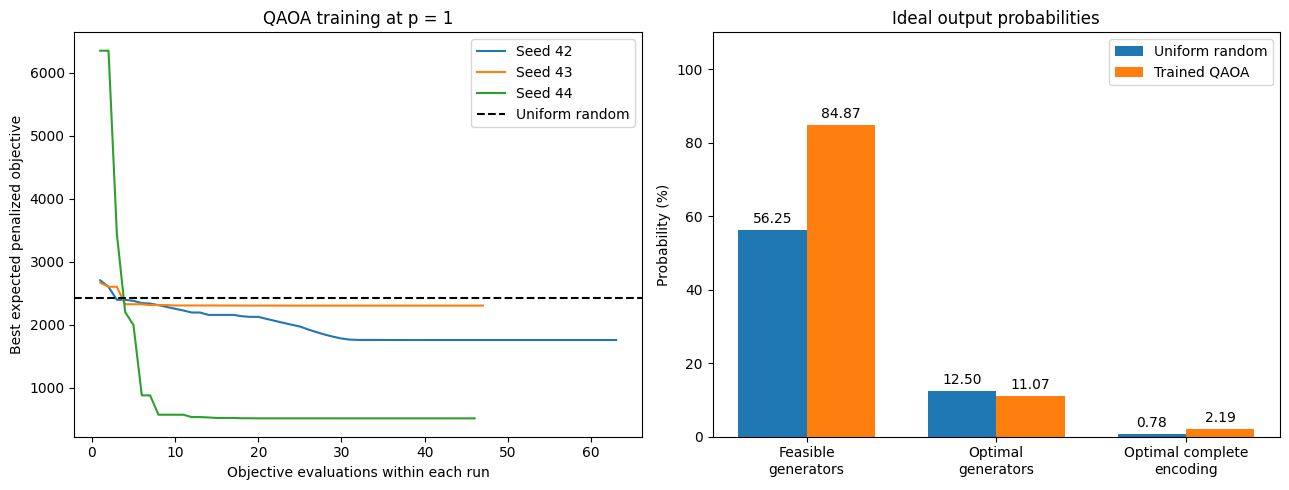

Figure saved to: /Users/wetlab/Documents/gridq-personal/results/qaoa_training_p1.png


In [11]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create an output folder inside the notebook's working directory.
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot the best objective encountered up to each evaluation.
for run in training_runs:
    recorded_energies = [
        item["expected_energy"]
        for item in run["evaluations"]
    ]
    best_so_far = np.minimum.accumulate(recorded_energies)

    axes[0].plot(
        np.arange(1, len(best_so_far) + 1),
        best_so_far,
        label=f"Seed {run['seed']}",
    )

axes[0].axhline(
    uniform_metrics["expected_energy"],
    color="black",
    linestyle="--",
    label="Uniform random",
)
axes[0].set_xlabel("Objective evaluations within each run")
axes[0].set_ylabel("Best expected penalized objective")
axes[0].set_title("QAOA training at p = 1")
axes[0].legend()

# Compare probabilities using the selected training run.
metric_keys = [
    "feasibility_probability",
    "optimal_generator_probability",
    "optimal_encoded_probability",
]
metric_labels = [
    "Feasible\ngenerators",
    "Optimal\ngenerators",
    "Optimal complete\nencoding",
]

positions = np.arange(len(metric_keys))
width = 0.36

random_values = [
    100 * uniform_metrics[key] for key in metric_keys
]
trained_values = [
    100 * trained_metrics[key] for key in metric_keys
]

random_bars = axes[1].bar(
    positions - width / 2,
    random_values,
    width,
    label="Uniform random",
)
trained_bars = axes[1].bar(
    positions + width / 2,
    trained_values,
    width,
    label="Trained QAOA",
)

axes[1].bar_label(random_bars, fmt="%.2f", padding=3)
axes[1].bar_label(trained_bars, fmt="%.2f", padding=3)
axes[1].set_xticks(positions, metric_labels)
axes[1].set_ylabel("Probability (%)")
axes[1].set_ylim(0, 110)
axes[1].set_title("Ideal output probabilities")
axes[1].legend()

fig.tight_layout()

figure_path = results_dir / "qaoa_training_p1.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")

plt.show()
print("Figure saved to:", figure_path.resolve())

## 11. Sampling Generator Decisions

The previous statevector calculations gave ideal probabilities.
Here, I draw 4,096 measurement samples from the trained circuit using
the Aer simulator, without gate noise.

A shot is one circuit execution followed by measurement. Counts record
how often each bitstring appears. Dividing counts by the number of shots
gives estimated probabilities.

Finite-shot estimates can differ from the ideal probabilities even
without gate noise. This is sampling variation.

With our measurement mapping, Qiskit displays bitstrings in the order:

b3 b2 b1 b0 x3 x2 x1 x0

I decode each bitstring into qubit order before interpreting generators.
I also combine counts across all slack assignments to obtain the
measurement frequency of each generator selection.

Finding an optimal selection among many samples is different from
having a high probability of producing it in a single shot.

In [12]:
from qiskit import transpile
from qiskit_aer import AerSimulator
import json

shots = 4096
sampling_seed = 2026

# Keep the original trained circuit available without measurements.
measured_circuit = trained_circuit.copy()
measured_circuit.measure_all()

ideal_simulator = AerSimulator()

compiled_circuit = transpile(
    measured_circuit,
    ideal_simulator,
    optimization_level=1,
    seed_transpiler=42,
)

sampling_result = ideal_simulator.run(
    compiled_circuit,
    shots=shots,
    seed_simulator=sampling_seed,
).result()

sample_counts = sampling_result.get_counts()
assert sum(sample_counts.values()) == shots

# Convert counts into the same basis-index order used earlier.
sampled_probabilities = np.zeros(2**num_variables)

generator_counts = {
    bits: 0
    for bits in product([0, 1], repeat=len(costs))
}

for displayed_bits, count in sample_counts.items():
    basis_index = int(displayed_bits, 2)
    sampled_probabilities[basis_index] = count / shots

    generator_bits = tuple(
        (basis_index >> i) & 1
        for i in range(len(costs))
    )
    generator_counts[generator_bits] += count

sampled_metrics = evaluate_probabilities(sampled_probabilities)

print_metrics("IDEAL PROBABILITIES", trained_metrics)
print_metrics("ESTIMATES FROM 4096 SHOTS", sampled_metrics)

print("\nGenerator selections, combining all slack assignments:")
print("Selection | Count | Capacity | Cost | Feasible")

for bits, count in sorted(
    generator_counts.items(),
    key=lambda item: item[1],
    reverse=True,
):
    capacity = sum(b * c for b, c in zip(bits, capacities))
    cost = sum(b * c for b, c in zip(bits, costs))
    label = "".join(str(b) for b in bits)

    print(
        f"{label} | {count:4d} | {capacity:2d} | "
        f"{cost:2d} | {'Yes' if capacity >= demand else 'No'}"
    )

# Save the raw measurements and the experiment settings.
sampling_path = results_dir / "ideal_sampling_p1.json"

sampling_record = {
    "shots": shots,
    "sampling_seed": sampling_seed,
    "transpiler_seed": 42,
    "qaoa_depth": 1,
    "gamma": float(trained_gamma),
    "beta": float(trained_beta),
    "displayed_bit_order": "b3 b2 b1 b0 x3 x2 x1 x0",
    "counts": {
        str(bits): int(count)
        for bits, count in sample_counts.items()
    },
    "ideal_metrics": trained_metrics,
    "sampled_metrics": sampled_metrics,
}

sampling_path.write_text(
    json.dumps(sampling_record, indent=2),
    encoding="utf-8",
)

print("\nPASS: All 4096 shots were counted.")
print("Sampling results saved to:", sampling_path.resolve())


IDEAL PROBABILITIES
Expected penalized objective: 516.4466
Feasibility probability: 84.87%
Optimal generator probability: 11.07%
Optimal encoded probability: 2.18739%

ESTIMATES FROM 4096 SHOTS
Expected penalized objective: 506.7761
Feasibility probability: 84.35%
Optimal generator probability: 11.35%
Optimal encoded probability: 2.05078%

Generator selections, combining all slack assignments:
Selection | Count | Capacity | Cost | Feasible
1111 |  630 | 18 | 22 | Yes
0111 |  508 | 16 | 19 | Yes
1011 |  435 | 14 | 17 | Yes
1101 |  394 | 13 | 16 | Yes
1110 |  386 | 11 | 14 | Yes
0011 |  339 | 12 | 14 | Yes
0101 |  298 | 11 | 13 | Yes
0110 |  264 |  9 | 11 | Yes
1001 |  201 |  9 | 11 | Yes
1010 |  173 |  7 |  9 | No
0001 |  150 |  7 |  8 | No
1100 |  120 |  6 |  8 | No
0010 |   99 |  5 |  6 | No
0100 |   63 |  4 |  5 | No
1000 |   25 |  2 |  3 | No
0000 |   11 |  0 |  0 | No

PASS: All 4096 shots were counted.
Sampling results saved to: /Users/wetlab/Documents/gridq-personal/results/idea

## 12. Adding Simulated Gate Noise

I keep the trained angles fixed and investigate how gate noise changes
the output distribution. This tests the robustness of the same circuit;
I do not retrain it under noise.

I use a depolarizing channel:

$$
\mathcal{E}(\rho)=(1-\lambda)\rho+\lambda I/2^n.
$$

Here, rho describes the state of the affected n qubits. The channel
mixes that state with a maximally mixed state, reducing its information.

Before applying noise, I compile the circuit into these gates:

- RZ: rotation about Z.
- SX: the square root of X; applying SX twice gives X.
- X: bit flip.
- CX: controlled bit flip.

The noise model applies:

- Depolarizing strength lambda after each SX or X gate.
- Depolarizing strength 2 lambda after each CX gate.
- No error after RZ gates.

These are chosen modeling assumptions, not measured hardware properties.
The factor of two for CX represents a deliberately stronger two-qubit
noise channel.

I use density-matrix simulation to calculate output probabilities
directly. This includes the modeled gate noise without finite-shot
sampling variation.

Before interpreting noise results, I verify that compilation and
zero-noise density-matrix simulation preserve the ideal probabilities.

In [13]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

noise_basis = ["rz", "sx", "x", "cx"]

# Compile once so every noise level uses exactly the same gates.
noise_test_circuit = transpile(
    trained_circuit,
    basis_gates=noise_basis,
    optimization_level=1,
    seed_transpiler=42,
)

print("Compiled gate counts:", dict(noise_test_circuit.count_ops()))

compiled_probabilities = Statevector.from_instruction(
    noise_test_circuit
).probabilities()

assert np.allclose(
    compiled_probabilities,
    trained_probabilities,
    rtol=0,
    atol=1e-9,
)

# Confirm that gates receiving noise actually occur in this circuit.
assert noise_test_circuit.count_ops().get("sx", 0) > 0
assert noise_test_circuit.count_ops().get("cx", 0) > 0

print("PASS: Compilation preserves the ideal probabilities.")

def make_noise_model(noise_strength):
    if not 0 <= noise_strength <= 0.5:
        raise ValueError("Use a noise strength between 0 and 0.5.")

    model = NoiseModel(basis_gates=noise_basis)

    if noise_strength > 0:
        one_qubit_error = depolarizing_error(noise_strength, 1)
        two_qubit_error = depolarizing_error(2 * noise_strength, 2)

        model.add_all_qubit_quantum_error(
            one_qubit_error, ["sx", "x"]
        )
        model.add_all_qubit_quantum_error(
            two_qubit_error, ["cx"]
        )

    return model

def simulate_noise_probabilities(noise_strength):
    simulator = AerSimulator(
        method="density_matrix",
        noise_model=make_noise_model(noise_strength),
        max_parallel_threads=1,
    )

    circuit = noise_test_circuit.copy()
    circuit.save_probabilities(label="output_probabilities")

    # No measurements: retrieve probabilities directly.
    result = simulator.run(circuit, shots=1).result()

    if not result.success:
        raise RuntimeError(str(result))

    probabilities = np.asarray(
        result.data(0)["output_probabilities"],
        dtype=float,
    )

    assert np.isclose(probabilities.sum(), 1.0)
    return probabilities

zero_noise_probabilities = simulate_noise_probabilities(0.0)

assert np.allclose(
    zero_noise_probabilities,
    trained_probabilities,
    rtol=0,
    atol=1e-9,
)

print("PASS: Zero-noise density simulation matches the ideal circuit.")

test_noise_strength = 0.01
noisy_probabilities = simulate_noise_probabilities(test_noise_strength)
noisy_metrics = evaluate_probabilities(noisy_probabilities)

print_metrics("IDEAL TRAINED CIRCUIT", trained_metrics)
print_metrics("NOISY CIRCUIT: lambda = 0.01", noisy_metrics)

Compiled gate counts: {'rz': 68, 'cx': 56, 'sx': 24}
PASS: Compilation preserves the ideal probabilities.
PASS: Zero-noise density simulation matches the ideal circuit.

IDEAL TRAINED CIRCUIT
Expected penalized objective: 516.4466
Feasibility probability: 84.87%
Optimal generator probability: 11.07%
Optimal encoded probability: 2.18739%

NOISY CIRCUIT: lambda = 0.01
Expected penalized objective: 908.6909
Feasibility probability: 77.12%
Optimal generator probability: 11.90%
Optimal encoded probability: 1.63100%


## 13. Noise Sweep with Fixed Trained Angles

I evaluate the selected p = 1 circuit at depolarizing strengths:

0, 0.005, 0.01, 0.02, and 0.05.

At each level, SX and X gates receive strength lambda, and CX gates
receive strength 2 lambda. RZ gates remain noiseless.

The angles and compiled circuit stay fixed throughout this experiment.
This isolates the effect of changing the noise strength.

I record:

- Expected penalized objective.
- Feasibility probability.
- Optimal generator probability.
- Optimal encoded probability.

The probabilities come directly from density-matrix simulation.
Therefore, these results have no finite-shot sampling variation;
repeating the same calculation with different sampling seeds is unnecessary.

Noise need not make every individual metric worse. For example, mixing
toward a more uniform distribution could increase a success probability
that initially lies below the uniform baseline. I interpret all four
metrics together.

Evaluating lambda = 0.0 ...
Evaluating lambda = 0.005 ...
Evaluating lambda = 0.01 ...
Evaluating lambda = 0.02 ...
Evaluating lambda = 0.05 ...


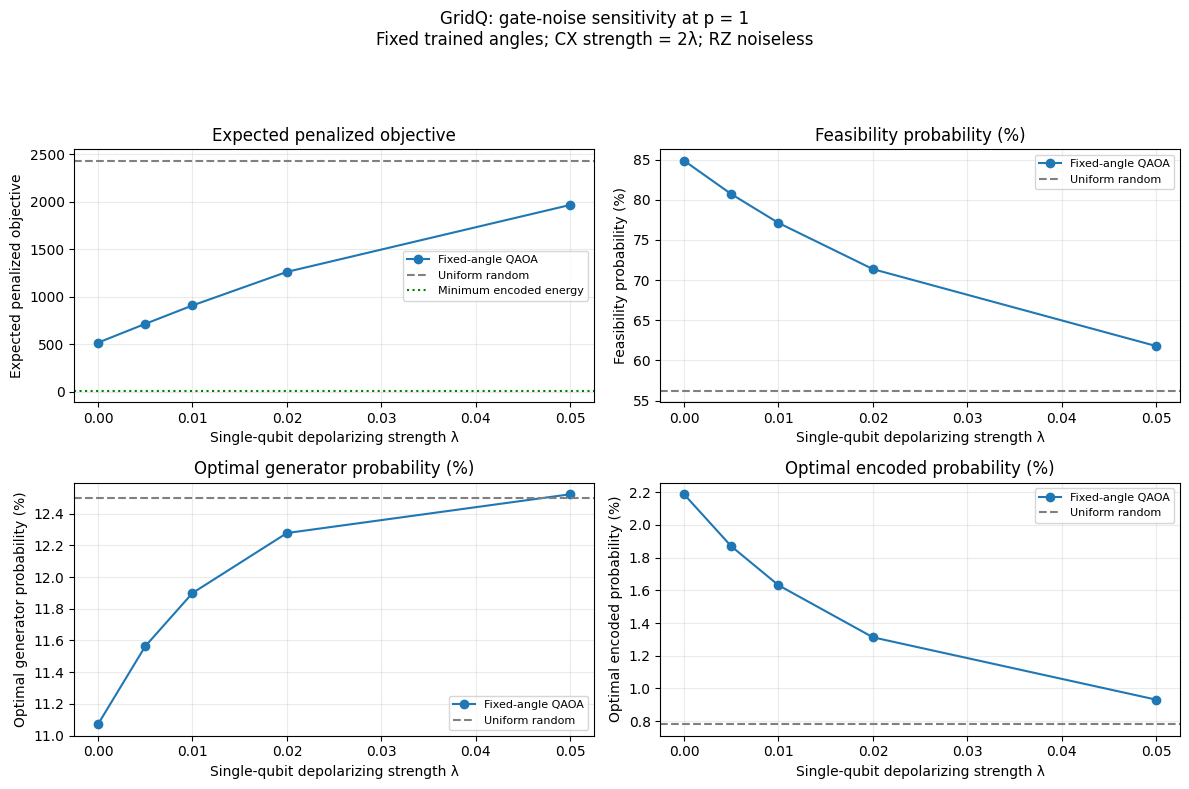


NOISE SWEEP SUMMARY
λ=0.000 | E=516.45 | feasible=84.87% | optimal generators=11.07% | optimal encoding=2.187%
λ=0.005 | E=714.80 | feasible=80.71% | optimal generators=11.56% | optimal encoding=1.869%
λ=0.010 | E=908.69 | feasible=77.12% | optimal generators=11.90% | optimal encoding=1.631%
λ=0.020 | E=1262.58 | feasible=71.37% | optimal generators=12.28% | optimal encoding=1.313%
λ=0.050 | E=1968.58 | feasible=61.79% | optimal generators=12.52% | optimal encoding=0.931%

Saved summary: /Users/wetlab/Documents/gridq-personal/results/noise_sweep_p1.csv
Saved figure: /Users/wetlab/Documents/gridq-personal/results/noise_sweep_p1.png


In [14]:
import csv

noise_levels = [0.0, 0.005, 0.01, 0.02, 0.05]
noise_sweep_rows = []
noise_sweep_probabilities = []

for strength in noise_levels:
    print(f"Evaluating lambda = {strength} ...", flush=True)

    # Reuse the two distributions already calculated.
    if strength == 0.0:
        probabilities = zero_noise_probabilities.copy()
    elif strength == test_noise_strength:
        probabilities = noisy_probabilities.copy()
    else:
        probabilities = simulate_noise_probabilities(strength)

    metrics = evaluate_probabilities(probabilities)

    noise_sweep_rows.append({
        "lambda_1q": strength,
        "lambda_cx": 2 * strength,
        **metrics,
    })
    noise_sweep_probabilities.append(probabilities.copy())

# Save the numerical summary.
csv_path = results_dir / "noise_sweep_p1.csv"

with csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=list(noise_sweep_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(noise_sweep_rows)

# Save full distributions and settings for reproducibility.
np.savez(
    results_dir / "noise_sweep_p1_distributions.npz",
    noise_levels=np.array(noise_levels),
    probabilities=np.array(noise_sweep_probabilities),
)

settings = {
    "qaoa_depth": 1,
    "selected_training_seed": int(best_training_run["seed"]),
    "gamma": float(trained_gamma),
    "beta": float(trained_beta),
    "energy_scale": float(energy_scale),
    "transpiler_seed": 42,
    "compiled_gate_counts": {
        str(gate): int(count)
        for gate, count in noise_test_circuit.count_ops().items()
    },
    "one_qubit_noisy_gates": ["sx", "x"],
    "two_qubit_noisy_gates": ["cx"],
    "noiseless_basis_gates": ["rz"],
    "cx_noise_multiplier": 2,
    "simulation_method": "density_matrix",
    "angles_retrained_under_noise": False,
}

(results_dir / "noise_sweep_p1_settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8",
)

# Plot each metric separately.
plot_specs = [
    ("expected_energy", "Expected penalized objective", False),
    ("feasibility_probability", "Feasibility probability (%)", True),
    (
        "optimal_generator_probability",
        "Optimal generator probability (%)",
        True,
    ),
    (
        "optimal_encoded_probability",
        "Optimal encoded probability (%)",
        True,
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (key, title, is_probability) in zip(axes.flat, plot_specs):
    multiplier = 100 if is_probability else 1
    values = [
        multiplier * row[key]
        for row in noise_sweep_rows
    ]

    ax.plot(
        noise_levels,
        values,
        marker="o",
        label="Fixed-angle QAOA",
    )
    ax.axhline(
        multiplier * uniform_metrics[key],
        color="gray",
        linestyle="--",
        label="Uniform random",
    )

    if key == "expected_energy":
        ax.axhline(
            best_energy,
            color="green",
            linestyle=":",
            label="Minimum encoded energy",
        )

    ax.set_xlabel("Single-qubit depolarizing strength λ")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "GridQ: gate-noise sensitivity at p = 1\n"
    "Fixed trained angles; CX strength = 2λ; RZ noiseless"
)
fig.tight_layout(rect=[0, 0, 1, 0.92])

figure_path = results_dir / "noise_sweep_p1.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nNOISE SWEEP SUMMARY")
for row in noise_sweep_rows:
    print(
        f"λ={row['lambda_1q']:.3f} | "
        f"E={row['expected_energy']:.2f} | "
        f"feasible={row['feasibility_probability']:.2%} | "
        f"optimal generators="
        f"{row['optimal_generator_probability']:.2%} | "
        f"optimal encoding="
        f"{row['optimal_encoded_probability']:.3%}"
    )

print("\nSaved summary:", csv_path.resolve())
print("Saved figure:", figure_path.resolve())

## 14. Discussion of Results

### Ideal QAOA

Among three p = 1 training starts, seed 44 produced the lowest expected
penalized objective. The selected circuit reduced this objective from
2435.00 for uniform random assignments to 516.45.

Its feasibility probability was 84.87%, compared with the uniform
baseline of 56.25%. Its optimal encoded probability was approximately
2.187%, compared with 0.78125% for uniform assignments.

However, its optimal generator probability was 11.07%, below the uniform
baseline of 12.50%. The circuit therefore improved feasibility and the
encoded objective without improving every measure of solution quality.

### Finite-Shot Sampling

With 4,096 ideal measurement shots, the observed feasibility was 84.35%,
optimal generator frequency was 11.35%, and optimal encoded frequency
was approximately 2.051%.

These estimates were close to the ideal probabilities. Their differences
illustrate finite-shot sampling variation.

### Effect of Gate Noise

| Single-qubit strength λ | Expected objective | Feasible generators | Optimal generators | Optimal complete encoding |
|---:|---:|---:|---:|---:|
| 0.000 | 516.45 | 84.87% | 11.07% | 2.187% |
| 0.005 | 714.80 | 80.71% | 11.56% | 1.869% |
| 0.010 | 908.69 | 77.12% | 11.90% | 1.631% |
| 0.020 | 1262.58 | 71.37% | 12.28% | 1.313% |
| 0.050 | 1968.58 | 61.79% | 12.52% | 0.931% |

As noise increased, expected penalized objective increased, feasibility
decreased, and optimal encoded probability decreased.

Optimal generator probability instead increased toward the uniform
baseline of 12.50%. At λ = 0.05, it was approximately 12.52%.
This small excess over the baseline alone does not demonstrate an advantage.

The trends are consistent with the distribution moving toward uniform
mixing. These four summary metrics alone do not establish that the
entire distribution becomes progressively closer to uniform.

### Main Finding

The apparent effect of noise depends on the metric being measured.
Generator success alone would suggest a small improvement, whereas
feasibility, expected objective, and correct complete encoding show
degradation.

This distinction matters because generator decisions and auxiliary
slack bits play different roles in the encoded problem.

### Scope and Limitations

This experiment uses one synthetic four-generator instance, depth p = 1,
and three optimizer starts. The exact classical solution is inexpensive
to obtain by enumeration.

The experiments use classical simulation rather than quantum hardware.
The noise model is simplified: SX and X gates receive depolarizing
strength λ, CX gates receive strength 2λ, and RZ gates remain noiseless.

Angles were trained without noise and held fixed during the noise sweep.
The results describe sensitivity under this protocol; they do not
establish how well noise-aware retraining would perform.

The project demonstrates problem encoding, QAOA simulation, and
metric-dependent noise effects. It does not establish quantum speedup.